In [59]:
import IPython
import sklearn as sk
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("IPython", IPython.__version__)
print("scikit-learn", sk.__version__)
print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)

IPython 7.34.0
scikit-learn 1.6.1
numpy 2.1.3
matplotlib 3.10.0


In [60]:
from sklearn import datasets
iris = datasets.load_iris()
X_iris, y_iris = iris.data, iris.target
print(X_iris.shape, y_iris.shape)
print(X_iris[0], y_iris[0])

(150, 4) (150,)
[5.1 3.5 1.4 0.2] 0


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Get the dataset with the first two attributes(the first two columns or the
# first two features)
X, y = X_iris[:,:2], y_iris
# Split the dataset into training data and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=33)
print(X_train.shape, y_train.shape)
# Standarized the features
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)


(112, 2) (112,)


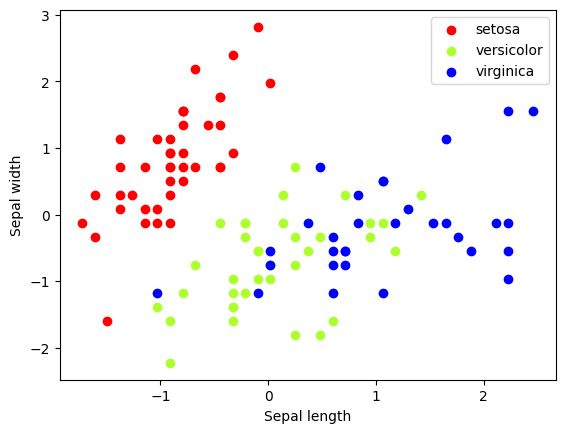

In [63]:
colors = ["red", "greenyellow", "blue"]
for i in range(len(colors)):
  px = X_train[:,0][y_train == i]
  py = X_train[:,1][y_train == i]
  plt.scatter(px, py, c=colors[i])

  plt.legend(iris.target_names)
  plt.xlabel("Sepal length")
  plt.ylabel("Sepal width")

In [64]:
from sklearn.linear_model import SGDClassifier
# Create the linear model classifier
clf = SGDClassifier()
# Fit (which means train)
clf.fit(X_train,y_train)
print(clf.coef_)
print(clf.intercept_)

[[-32.33727751   8.73363203]
 [  2.24808374  -2.54268637]
 [  6.17804648   1.20413028]]
[-17.88517823  -3.08167568  -8.46396988]


[-2.22429277 -1.72429277 -1.22429277 -0.72429277 -0.22429277  0.27570723
  0.77570723  1.27570723  1.77570723  2.27570723  2.77570723] [-6.1878488  -4.33654126 -2.48523373 -0.6339262   1.21738133  3.06868886
  4.91999639  6.77130392  8.62261145 10.47391898 12.32522651]
[-2.22429277 -1.72429277 -1.22429277 -0.72429277 -0.22429277  0.27570723
  0.77570723  1.27570723  1.77570723  2.27570723  2.77570723] [-3.17855642 -2.73648779 -2.29441917 -1.85235054 -1.41028192 -0.96821329
 -0.52614467 -0.08407604  0.35799258  0.80006121  1.24212983]
[-2.22429277 -1.72429277 -1.22429277 -0.72429277 -0.22429277  0.27570723
  0.77570723  1.27570723  1.77570723  2.27570723  2.77570723] [18.44132186 15.87596552 13.31060919 10.74525285  8.17989651  5.61454017
  3.04918383  0.4838275  -2.08152884 -4.64688518 -7.21224152]


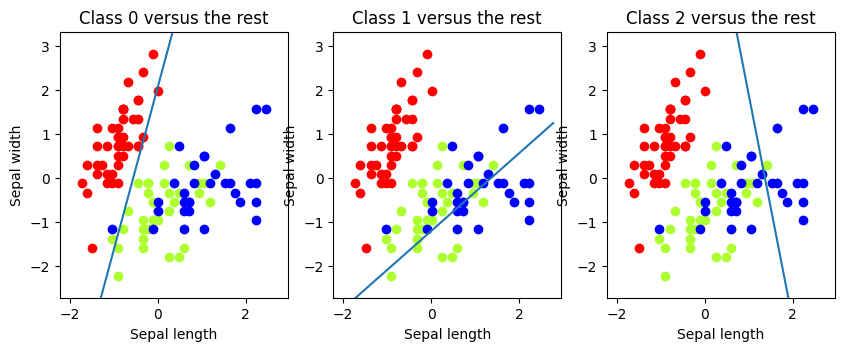

In [65]:
x_min, x_max = X_train[:, 0].min()- .5, X_train[:, 0].max() + .5
y_min, y_max = X_train[:, 1].min() - .5, X_train[:, 1].max() + .5
xs = np.arange(x_min,x_max,0.5)
fig, axes = plt.subplots(1,3)
fig.set_size_inches(10,6)
for i in [0,1,2]:
    axes[i].set_aspect('equal')
    axes[i].set_title('Class ' + str(i) + ' versus the rest')
    axes[i].set_xlabel('Sepal length')
    axes[i].set_ylabel('Sepal width')
    axes[i].set_xlim(x_min, x_max)
    axes[i].set_ylim(y_min, y_max)
    plt.sca(axes[i])
    for j in range(len(colors)):
        px = X_train[:, 0][y_train == j]
        py = X_train[:, 1][y_train == j]
        plt.scatter(px, py, c=colors[j])
    ys = (-clf.intercept_[i]-xs*clf.coef_[i,0])/clf.coef_[i,1]

    print(xs, ys)
    plt.plot(xs, ys)

In [66]:
print(clf.predict(scaler.transform([[4.7, 3.1]])))
print(clf.decision_function(scaler.transform([[4.7, 3.1]])))


[0]
[[ 23.58155333  -6.12796582 -16.14349442]]


In [68]:
from sklearn import metrics
y_train_pred = clf.predict(X_train)
print(metrics.accuracy_score(y_train, y_train_pred))

0.7946428571428571


In [70]:
y_pred = clf.predict(X_test)
print(metrics.accuracy_score(y_test, y_pred))

0.6052631578947368


In [71]:
print(metrics.classification_report(y_test, y_pred, target_names=iris.target_names))
print(metrics.confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         8
  versicolor       0.42      1.00      0.59        11
   virginica       1.00      0.21      0.35        19

    accuracy                           0.61        38
   macro avg       0.81      0.74      0.65        38
weighted avg       0.83      0.61      0.56        38

[[ 8  0  0]
 [ 0 11  0]
 [ 0 15  4]]


In [77]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline

# create a composite estimator made by a pipeline of the standarization and the linear model
clf = Pipeline([
        ('scaler', StandardScaler()),
        ('linear_model', SGDClassifier())
])
# create a k-fold croos validation iterator of k=5 folds
cv = KFold(5, shuffle=True, random_state=33)
# by default the score used is the one returned by score method of the estimator (accuracy)
scores = cross_val_score(clf, X, y, cv=cv)
print(scores)

[0.76666667 0.8        0.76666667 0.86666667 0.7       ]


In [79]:
from scipy.stats import sem

def mean_score(scores):
    """Print the empirical mean score and standard error of the mean."""
    return ("Mean score: {0:.3f} (+/-{1:.3f})").format(
        np.mean(scores), sem(scores))

print(mean_score(scores))

Mean score: 0.780 (+/-0.027)
